# HW2：伊斯坦堡公寓房價之多元線性回歸分析（CRISP-DM）

- **資料集**：Istanbul Apartment Prices 2026（Kaggle, brahimenesulusoy）
  <https://www.kaggle.com/datasets/brahimenesulusoy/istanbul-apartment-prices-2026>
- **筆數 / 欄位**：24,767 筆、30 欄（可用特徵 > 13 個）
- **目標變數**：`price`（土耳其里拉 TRY），建模時使用 `log(price)`
- **方法**：簡單線性回歸（基準）→ 多元線性回歸 → 特徵選擇（Forward Stepwise-AIC、RFE、LassoCV）→ 評估 → 預測區間 → 部署（GitHub Pages）

> 🤖 **GPT 輔助內容**：本 notebook 之程式架構、特徵工程與文字說明由 AI 助理（Claude）協助產生，經作者檢閱與執行。

In [1]:
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression, LassoCV
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RNG = 42
FIG = "docs/assets"; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140, "savefig.bbox": "tight"})
ACC, ACC2, GREY = "#2563eb", "#f97316", "#64748b"
def save(name): plt.savefig(f"{FIG}/{name}.png"); plt.show()

## 1. Business Understanding（商業理解）

**問題**：伊斯坦堡房價在高通膨下波動劇烈，買方、賣方與仲介需要一個**透明、可解釋**的估價工具。

**目標**：以房屋的面積、房間數、樓層、屋齡、行政區、暖氣、產權等屬性，建立線性回歸模型預測公寓售價，並提供**預測區間**表達不確定性。

**成功標準**
- 測試集 R²（log 尺度）≥ 0.75
- 95% 預測區間的實際覆蓋率接近 95%
- 模型係數可解釋（例如「面積增加 1%，價格約增加 β%」）

**選用線性回歸的理由**：係數可直接解讀為各屬性的邊際價值；搭配 log 轉換後，係數代表百分比變化，適合房價這類右偏資料。

## 2. Data Understanding（資料理解）

In [2]:
raw = pd.read_csv("data/istanbul_apartment_prices_2026.csv", encoding="utf-8-sig")
print(raw.shape)
raw.head()

(24767, 30)


,listing_id,price,price_per_sqm,district,neighborhood,rooms,halls,total_rooms,gross_sqm,net_sqm,...,usage_status,is_in_complex,complex_name,orientation,maintenance_fee,credit_eligible,deed_status,exchange,last_updated,scraped_at
0,54895-1121,15900000,165625.00,Adalar,Maden,3,1,4,138.0,96.0,...,Vacant,0,NaN,"North, South, East, West",2500.0,Not Eligible,Land Title,No,2026-03-11,2026-03-14T20:38:29
1,54895-1103,40000000,266666.67,Adalar,Nizam,4,1,5,199.0,150.0,...,Vacant,1,NaN,"North, South, East, West",10000.0,Eligible,Construction Easement,No,2026-03-05,2026-03-14T20:38:36
2,54895-1148,17850000,220370.37,Adalar,Nizam,2,1,3,107.0,81.0,...,Vacant,0,NaN,"North, East, West",1000.0,Eligible,Condominium Title,No,2026-03-05,2026-03-14T20:38:47
3,12854-258,16000000,81632.65,Adalar,Heybeliada,3,1,4,200.0,196.0,...,Owner-occupied,0,NaN,"North, West",NaN,Eligible,Condominium Title,No,2026-03-14,2026-03-14T20:38:56
4,121334-99,14000000,96551.72,Adalar,Nizam,4,1,5,160.0,145.0,...,Vacant,0,NaN,NaN,400.0,Eligible,Condominium Title,No,2026-03-14,2026-03-14T20:39:04


In [3]:
info = pd.DataFrame({"dtype": raw.dtypes.astype(str),
                     "missing_%": (raw.isna().mean()*100).round(1),
                     "n_unique": raw.nunique()})
info.sort_values("missing_%", ascending=False)

,dtype,missing_%,n_unique
complex_name,object,84.8,1976
floor_category,object,70.1,16
maintenance_fee,float64,63.7,497
building_type,object,58.8,7
building_condition,object,55.9,3
fuel_type,object,55.9,4
last_updated,object,48.0,87
orientation,object,21.5,16
floor,float64,7.7,24
exchange,object,6.4,2


In [4]:
raw[["price","price_per_sqm","gross_sqm","net_sqm","rooms","total_floors","building_age","bathroom_count"]].describe(
    percentiles=[.01,.5,.99]).T.round(1)

,count,mean,std,min,1%,50%,99%,max
price,24767.0,13429845.6,141484342.5,24000.0,1625000.0,6750000.0,76000000.0,1.150000e+10
price_per_sqm,24767.0,132608.9,1967747.1,292.7,18974.7,72500.0,436363.6,1.600000e+08
gross_sqm,24767.0,126.3,58.2,1.0,50.0,110.0,327.7,9.090000e+02
net_sqm,24767.0,107.5,49.9,1.0,40.0,95.0,280.0,9.000000e+02
rooms,24767.0,2.6,1.3,1.0,1.0,2.0,6.0,1.140000e+02
total_floors,24766.0,6.6,6.7,1.0,2.0,5.0,30.0,4.500000e+02
building_age,24767.0,11.3,13.1,0.0,0.0,6.0,46.0,4.000000e+02
bathroom_count,24532.0,1.5,0.8,1.0,1.0,1.0,4.0,2.100000e+01


**觀察**
1. `price` 極度右偏（中位數約 675 萬，最大值 115 億），存在明顯輸入錯誤 → 需處理離群值並取 log。
2. `price_per_sqm = price / gross_sqm` 是由目標推導出的欄位 → **資料洩漏 (data leakage)，必須刪除**。
3. `complex_name`、`floor_category`、`maintenance_fee`、`building_type`、`fuel_type`、`building_condition` 缺值 > 50%。
4. `rooms`=114、`total_floors`=450、`building_age`=400 等為不合理值。

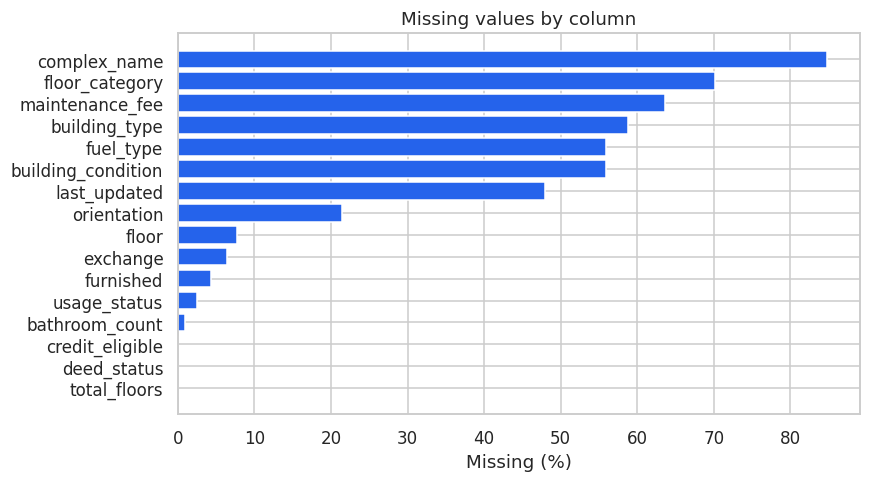

In [5]:
missing = raw.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]*100
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(missing.index[::-1], missing.values[::-1], color=ACC)
ax.set_xlabel("Missing (%)"); ax.set_title("Missing values by column")
save("01_missing")

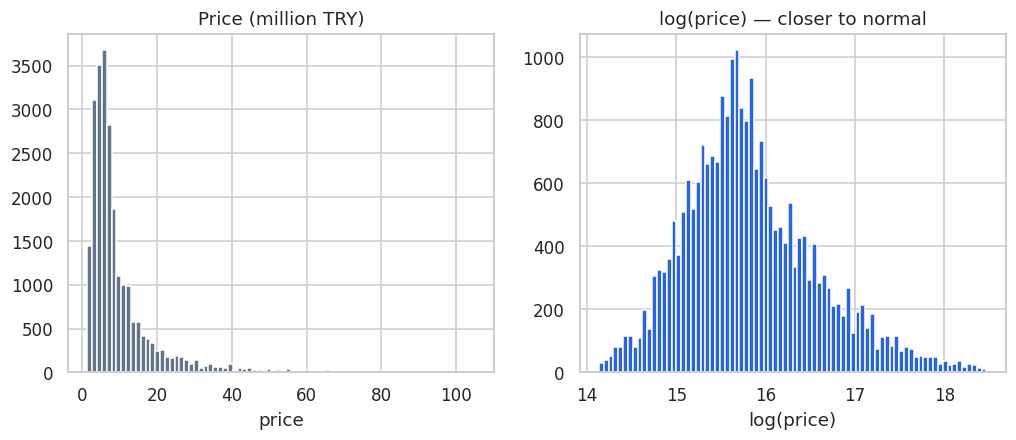

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
p = raw["price"]; p = p[p.between(p.quantile(.005), p.quantile(.995))]
axes[0].hist(p/1e6, bins=80, color=GREY); axes[0].set_title("Price (million TRY)"); axes[0].set_xlabel("price")
axes[1].hist(np.log(p), bins=80, color=ACC); axes[1].set_title("log(price) — closer to normal"); axes[1].set_xlabel("log(price)")
save("02_price_dist")

## 3. Data Preparation（資料準備）

**清理規則**
| 步驟 | 規則 | 理由 |
|---|---|---|
| 刪除洩漏 / 無用欄位 | `price_per_sqm`, `listing_id`, `last_updated`, `scraped_at`, `complex_name`, `neighborhood`(583 類) | 洩漏、ID、高基數 |
| 價格離群值 | 保留 0.5%–99.5% 分位數 | 去除輸入錯誤與極端豪宅 |
| 合理範圍 | 25 ≤ net_sqm ≤ 500、net ≤ gross、rooms ≤ 10、total_floors ≤ 60、building_age ≤ 100、floor ≤ total_floors | 物理上不合理 |
| 缺值 | 數值以中位數填補並加「是否缺值」旗標；類別補 `Missing` | 保留資訊而不丟樣本 |
| 衍生特徵 | `log_net_sqm`、`faces_south`、`n_directions`、`has_maint_fee`、`floor_ratio` | 捕捉非線性 / 方位價值 |
| 類別編碼 | One-hot（drop_first）；稀有類別併為 `Other` | 線性模型需數值輸入 |

In [7]:
df = raw.drop(columns=["price_per_sqm","listing_id","last_updated","scraped_at","complex_name","neighborhood"]).copy()
n0 = len(df)
lo, hi = df.price.quantile([.005, .995])
df = df[df.price.between(lo, hi)]
df = df[df.net_sqm.between(25, 500) & (df.net_sqm <= df.gross_sqm) & (df.rooms.between(1, 10))
        & (df.total_floors.between(1, 60)) & (df.building_age.between(0, 100))]
df = df[df.floor.isna() | (df.floor <= df.total_floors)]
df = df[df.district != "Çatalca"]   # only 7 listings
print(f"rows: {n0} -> {len(df)}  (removed {n0-len(df)}, {100*(n0-len(df))/n0:.1f}%)")

rows: 24767 -> 24403  (removed 364, 1.5%)


In [8]:
def lump(s, keep):
    return s.where(s.isin(keep), "Other")

def prepare(d):
    d = d.copy()
    d["floor_missing"] = d.floor.isna().astype(int)
    d["floor"] = d.floor.fillna(2.0)
    d["floor_ratio"] = (d.floor.clip(lower=0) / d.total_floors).clip(0, 1)
    d["bathroom_count"] = d.bathroom_count.fillna(1).clip(upper=6)
    d["has_maint_fee"] = (d.maintenance_fee.fillna(0) > 1).astype(int)
    o = d.orientation.fillna("")
    d["faces_south"] = o.str.contains("South").astype(int)
    d["n_directions"] = o.apply(lambda s: 0 if s == "" else len(s.split(",")))
    d["log_net_sqm"] = np.log(d.net_sqm)
    d["heating"] = lump(d.heating_type, ["Combi Boiler","Central (Metered)","Underfloor Heating","Central"])
    d["deed"] = lump(d.deed_status, ["Condominium Title","Construction Easement","Foreign Owner","Land Title","No Title Deed","Shared Title"])
    d["condition"] = d.building_condition.fillna("Missing")
    d["furnished"] = d.furnished.fillna("Missing")
    d["usage"] = lump(d.usage_status.fillna("Missing"), ["Vacant","Tenant-occupied","Owner-occupied"])
    d["credit"] = (d.credit_eligible == "Eligible").astype(int)
    d["exchange_yes"] = (d.exchange == "Yes").astype(int)
    return d

df = prepare(df)
df["log_price"] = np.log(df.price)

NUM = ["log_net_sqm","gross_sqm","rooms","halls","floor","floor_missing","floor_ratio","total_floors",
       "building_age","bathroom_count","is_in_complex","has_maint_fee","faces_south","n_directions",
       "credit","exchange_yes"]
CAT = ["district","heating","deed","condition","furnished","usage"]
print(len(NUM), "numeric +", len(CAT), "categorical feature groups =", len(NUM)+len(CAT))

16 numeric + 6 categorical feature groups = 22


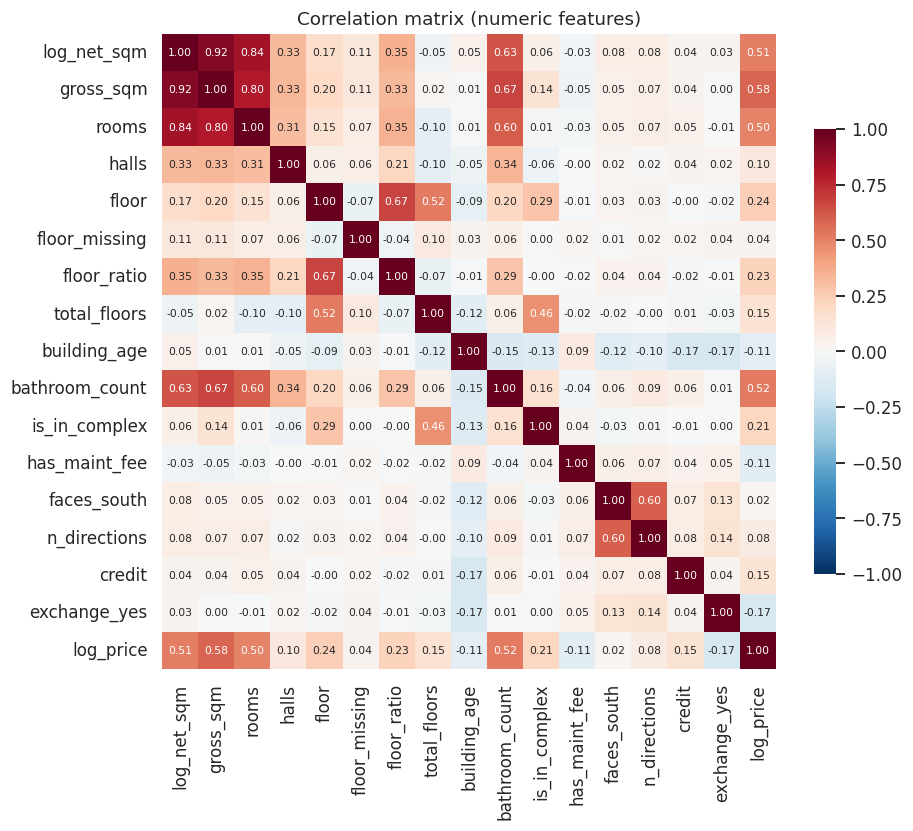

In [9]:
fig, ax = plt.subplots(figsize=(9, 7.5))
corr = df[NUM + ["log_price"]].corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax,
            cbar_kws={"shrink": .7})
ax.set_title("Correlation matrix (numeric features)")
save("03_corr")

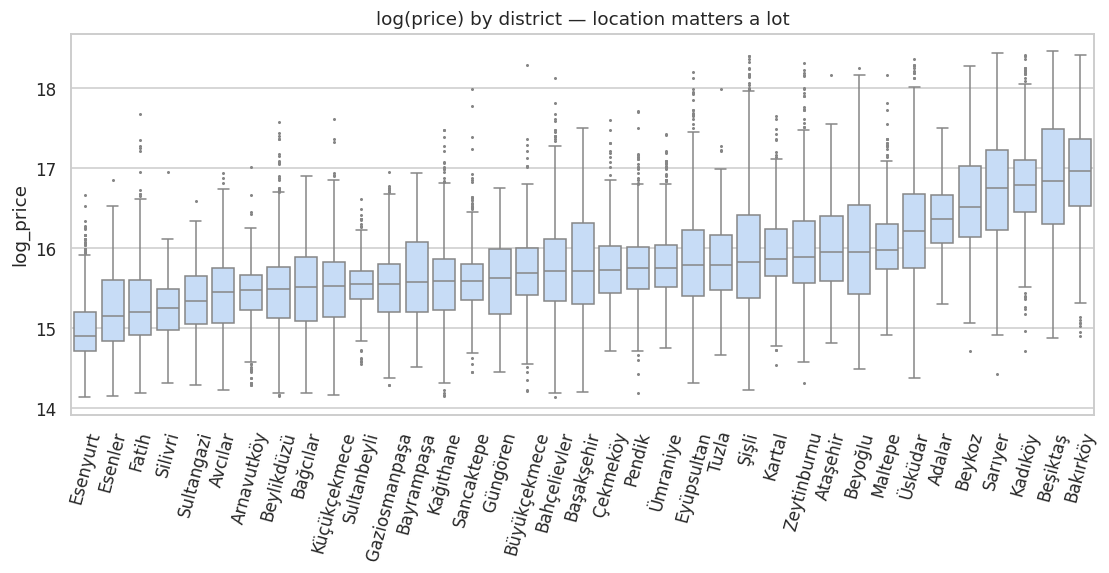

In [10]:
order = df.groupby("district").log_price.median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.boxplot(data=df, x="district", y="log_price", order=order, color="#bfdbfe", fliersize=1, ax=ax)
ax.tick_params(axis="x", rotation=75); ax.set_title("log(price) by district — location matters a lot"); ax.set_xlabel("")
save("04_district_box")

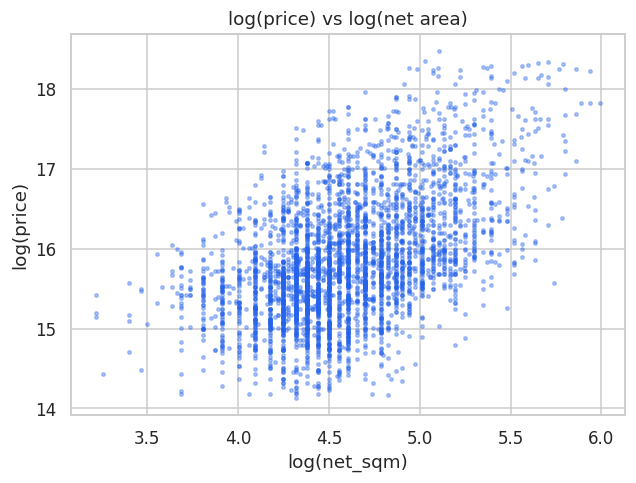

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
smp = df.sample(4000, random_state=RNG)
ax.scatter(smp.log_net_sqm, smp.log_price, s=5, alpha=.35, color=ACC)
ax.set_xlabel("log(net_sqm)"); ax.set_ylabel("log(price)"); ax.set_title("log(price) vs log(net area)")
save("05_scatter_area")

In [12]:
X_all = pd.get_dummies(df[NUM + CAT], columns=CAT, drop_first=True, dtype=float)
y_all = df.log_price.values
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, random_state=RNG)
print("train", X_tr.shape, " test", X_te.shape)
GROUPS = {f: [c for c in X_all.columns if c == f or c.startswith(f + "_")] for f in NUM + CAT}
GROUPS = {k: [c for c in v if (k in CAT) or c == k] for k, v in GROUPS.items()}

train (19522, 70)  test (4881, 70)


## 4. Modeling（建模）

### 4.1 基準模型：簡單線性回歸 log(price) ~ log(net_sqm)

In [13]:
def metrics(y, yhat, p):
    n = len(y); r2 = r2_score(y, yhat)
    return {"R2": r2, "adjR2": 1-(1-r2)*(n-1)/(n-p-1),
            "RMSE_log": np.sqrt(mean_squared_error(y, yhat)),
            "MAE_log": mean_absolute_error(y, yhat),
            "MAPE_price_%": 100*np.mean(np.abs(np.exp(yhat)-np.exp(y))/np.exp(y)),
            "MedAPE_price_%": 100*np.median(np.abs(np.exp(yhat)-np.exp(y))/np.exp(y))}

def fit_ols(cols):
    return sm.OLS(y_tr, sm.add_constant(X_tr[cols])).fit()

results = {}
slr = fit_ols(["log_net_sqm"])
results["SLR (log_net_sqm)"] = metrics(y_te, slr.predict(sm.add_constant(X_te[["log_net_sqm"]])), 1)
print(slr.summary().tables[1])

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          11.3587      0.054    208.766      0.000      11.252      11.465
log_net_sqm     0.9740      0.012     82.447      0.000       0.951       0.997


### 4.2 全特徵多元線性回歸（Full MLR）

In [14]:
full_cols = list(X_all.columns)
full = fit_ols(full_cols)
results["MLR full"] = metrics(y_te, full.predict(sm.add_constant(X_te[full_cols])), len(full_cols))
print(f"features: {len(full_cols)}   train adjR2={full.rsquared_adj:.4f}   AIC={full.aic:.0f}")

features: 70   train adjR2=0.8001   AIC=12358


### 4.3 特徵選擇 (Feature Selection)

使用三種方法互相驗證：
1. **Forward Stepwise（以 AIC 為準則，特徵群組層級）**：每次加入能使 AIC 下降最多的特徵群組（類別變數的所有 dummy 視為同一群組），直到 AIC 無法再下降。
2. **RFE（Recursive Feature Elimination）**：以標準化後的線性回歸反覆刪除係數絕對值最小的特徵。
3. **LassoCV（L1 正則化）**：以 5-fold CV 選 α，係數被壓成 0 的特徵視為不重要。

In [15]:
def group_cols(gs): return [c for g in gs for c in GROUPS[g]]

selected, remaining, history = [], list(GROUPS), []
best_aic = sm.OLS(y_tr, np.ones(len(y_tr))).fit().aic
while remaining:
    trials = [(fit_ols(group_cols(selected + [g])).aic, g) for g in remaining]
    aic, g = min(trials)
    if aic >= best_aic - 2:      # require meaningful improvement (ΔAIC > 2)
        break
    best_aic = aic; selected.append(g); remaining.remove(g)
    m = fit_ols(group_cols(selected))
    history.append({"step": len(selected), "added": g, "AIC": aic, "adjR2": m.rsquared_adj, "n_cols": len(group_cols(selected))})
hist = pd.DataFrame(history)
print("dropped groups:", remaining)
hist

dropped groups: ['floor_missing', 'total_floors', 'faces_south', 'n_directions']


,step,added,AIC,adjR2,n_cols
0,1,district,32777.898060,0.430137,36
1,2,gross_sqm,22451.125933,0.664251,37
2,3,building_age,19069.569907,0.717665,38
3,4,heating,16630.646546,0.750874,42
4,5,deed,15545.653796,0.764415,48
5,6,is_in_complex,14724.703030,0.774128,49
6,7,log_net_sqm,13722.931214,0.785437,50
7,8,bathroom_count,13415.351980,0.788802,51
8,9,halls,13181.466909,0.791328,52
9,10,floor_ratio,12955.676380,0.793738,53


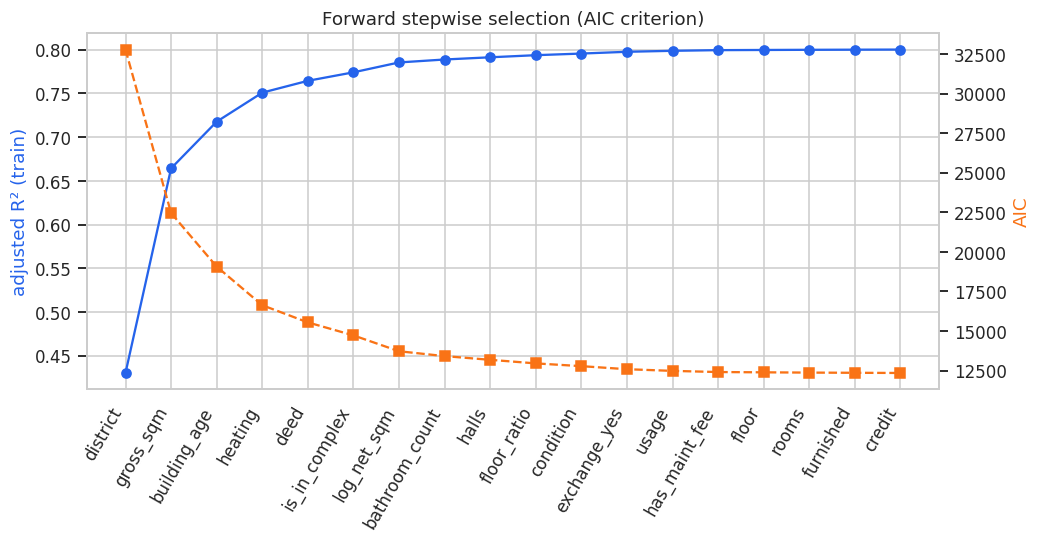

In [16]:
fig, ax1 = plt.subplots(figsize=(10, 4.2))
ax1.plot(hist.step, hist.adjR2, "o-", color=ACC); ax1.set_ylabel("adjusted R² (train)", color=ACC)
ax1.set_xticks(hist.step); ax1.set_xticklabels(hist.added, rotation=60, ha="right")
ax2 = ax1.twinx(); ax2.plot(hist.step, hist.AIC, "s--", color=ACC2); ax2.set_ylabel("AIC", color=ACC2); ax2.grid(False)
ax1.set_title("Forward stepwise selection (AIC criterion)")
save("06_stepwise")

In [17]:
sc = StandardScaler().fit(X_tr)
Xs_tr = sc.transform(X_tr)
rfe = RFE(LinearRegression(), n_features_to_select=30).fit(Xs_tr, y_tr)
rfe_cols = list(X_tr.columns[rfe.support_])
lasso = LassoCV(cv=5, random_state=RNG, n_alphas=60).fit(Xs_tr, y_tr)
lasso_coef = pd.Series(lasso.coef_, index=X_tr.columns)
lasso_cols = list(lasso_coef[lasso_coef != 0].index)
print(f"RFE kept {len(rfe_cols)} | Lasso alpha={lasso.alpha_:.5f} kept {len(lasso_cols)}/{X_tr.shape[1]}")

# compare at the feature-group level
cmp = pd.DataFrame({g: {"Stepwise-AIC": g in selected,
                        "RFE(30)": any(c in rfe_cols for c in GROUPS[g]),
                        "Lasso": any(c in lasso_cols for c in GROUPS[g])} for g in GROUPS}).T
cmp["votes"] = cmp.sum(axis=1)
cmp.sort_values("votes", ascending=False)

RFE kept 30 | Lasso alpha=0.00043 kept 67/70


,Stepwise-AIC,RFE(30),Lasso,votes
log_net_sqm,True,True,True,3
gross_sqm,True,True,True,3
heating,True,True,True,3
district,True,True,True,3
is_in_complex,True,True,True,3
building_age,True,True,True,3
deed,True,False,True,2
floor,True,False,True,2
halls,True,False,True,2
rooms,True,False,True,2


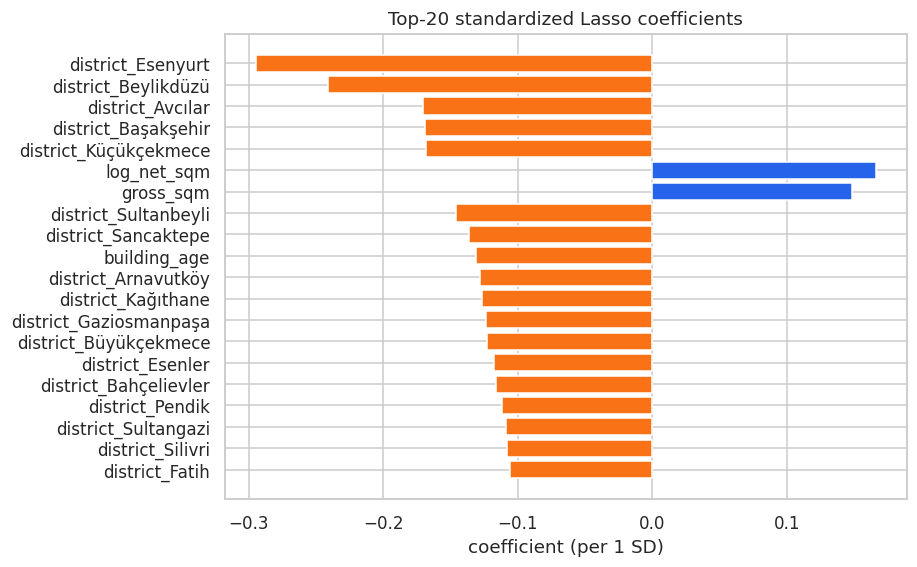

In [18]:
top = lasso_coef[lasso_coef.abs() > 0].abs().sort_values(ascending=False).head(20)
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index[::-1], lasso_coef[top.index][::-1], color=[ACC if v > 0 else ACC2 for v in lasso_coef[top.index][::-1]])
ax.set_title("Top-20 standardized Lasso coefficients"); ax.set_xlabel("coefficient (per 1 SD)")
save("07_lasso_coef")

### 4.4 最終模型（Stepwise-AIC 選出之特徵）

In [19]:
sel_cols = group_cols(selected)
final = fit_ols(sel_cols)
results["MLR stepwise (final)"] = metrics(y_te, final.predict(sm.add_constant(X_te[sel_cols])), len(sel_cols))
results["MLR RFE(30)"] = metrics(y_te, fit_ols(rfe_cols).predict(sm.add_constant(X_te[rfe_cols])), len(rfe_cols))
results["Lasso (CV)"] = metrics(y_te, lasso.predict(sc.transform(X_te)), len(lasso_cols))
print(final.summary().tables[0])

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.801
Model:                            OLS   Adj. R-squared:                  0.800
Method:                 Least Squares   F-statistic:                     1185.
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:58:51   Log-Likelihood:                -6108.4
No. Observations:               19522   AIC:                         1.235e+04
Df Residuals:                   19455   BIC:                         1.288e+04
Df Model:                          66                                         
Covariance Type:            nonrobust                                         


In [20]:
coef = pd.DataFrame({"coef": final.params, "p": final.pvalues, "CI_low": final.conf_int()[0], "CI_high": final.conf_int()[1]})
coef["effect_%"] = (np.exp(coef.coef) - 1) * 100
coef.drop(index="const").reindex(coef.drop(index="const").coef.abs().sort_values(ascending=False).index).head(25).round(4)

,coef,p,CI_low,CI_high,effect_%
district_Esenyurt,-1.6147,0.0,-1.6687,-1.5608,-80.1052
district_Silivri,-1.3549,0.0,-1.4239,-1.2859,-74.2031
district_Beylikdüzü,-1.3373,0.0,-1.3913,-1.2834,-73.7450
district_Arnavutköy,-1.2125,0.0,-1.2740,-1.1510,-70.2542
district_Avcılar,-1.1532,0.0,-1.2081,-1.0983,-68.4375
district_Başakşehir,-1.1457,0.0,-1.2014,-1.0900,-68.1991
district_Sultanbeyli,-1.1215,0.0,-1.1789,-1.0641,-67.4210
district_Büyükçekmece,-1.1048,0.0,-1.1638,-1.0457,-66.8708
district_Sultangazi,-1.0883,0.0,-1.1502,-1.0264,-66.3210
district_Esenler,-1.0417,0.0,-1.1009,-0.9826,-64.7157


**係數解讀（log-log / log-linear）**
- `log_net_sqm` 係數 β：淨面積增加 1%，價格約增加 β%（彈性）。
- 二元或 dummy 變數：價格變化約為 (e^β − 1)×100%，例如某行政區的 dummy 代表相對基準區（Adalar）的價差。
- `building_age`：每增加 1 年屋齡的百分比折價。

## 5. Evaluation（評估）

In [21]:
res = pd.DataFrame(results).T
kf = KFold(5, shuffle=True, random_state=RNG)
cv = {"SLR (log_net_sqm)": ["log_net_sqm"], "MLR full": full_cols, "MLR stepwise (final)": sel_cols, "MLR RFE(30)": rfe_cols}
res["CV5_R2"] = np.nan
for k, cols in cv.items():
    res.loc[k, "CV5_R2"] = cross_val_score(LinearRegression(), X_all[cols], y_all, cv=kf, scoring="r2").mean()
res["n_features"] = [1, len(full_cols), len(sel_cols), len(rfe_cols), len(lasso_cols)]
res.round(4)

,R2,adjR2,RMSE_log,MAE_log,MAPE_price_%,MedAPE_price_%,CV5_R2,n_features
SLR (log_net_sqm),0.2571,0.2569,0.6383,0.5044,54.8820,41.4356,0.2578,1
MLR full,0.8028,0.7999,0.3289,0.2492,25.9789,19.4666,0.7998,70
MLR stepwise (final),0.8027,0.8000,0.3289,0.2492,25.9750,19.4988,0.7999,66
MLR RFE(30),0.7337,0.7321,0.3821,0.2911,30.8272,22.4274,0.7270,30
Lasso (CV),0.8026,0.7998,0.3290,0.2495,26.0170,19.6182,NaN,67


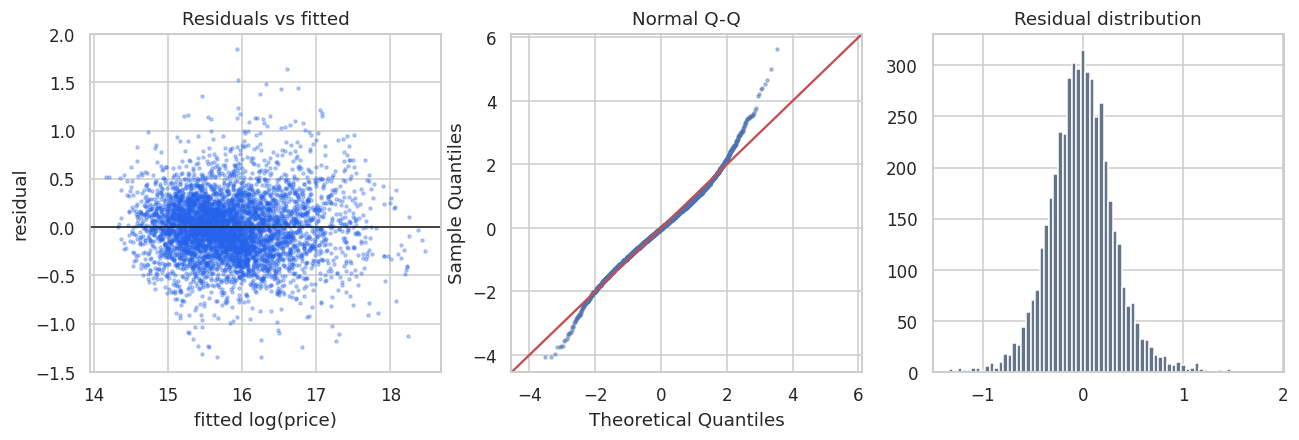

In [22]:
X_te_c = sm.add_constant(X_te[sel_cols])
yhat_te = final.predict(X_te_c)
resid = y_te - yhat_te
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter(yhat_te, resid, s=4, alpha=.3, color=ACC); axes[0].axhline(0, color="k", lw=1)
axes[0].set_xlabel("fitted log(price)"); axes[0].set_ylabel("residual"); axes[0].set_title("Residuals vs fitted")
sm.qqplot(resid, line="45", fit=True, ax=axes[1], markersize=2, alpha=.4); axes[1].set_title("Normal Q-Q")
axes[2].hist(resid, bins=70, color=GREY); axes[2].set_title("Residual distribution")
save("08_residuals")

In [23]:
num_in = [c for c in sel_cols if c in NUM]
Xv = sm.add_constant(X_tr[num_in])
vif = pd.DataFrame({"feature": num_in, "VIF": [variance_inflation_factor(Xv.values, i+1) for i in range(len(num_in))]})
vif.sort_values("VIF", ascending=False).round(2)

,feature,VIF
3,log_net_sqm,7.86
0,gross_sqm,6.99
10,rooms,3.62
6,floor_ratio,2.30
9,floor,2.24
4,bathroom_count,2.03
2,is_in_complex,1.27
5,halls,1.18
1,building_age,1.16
7,exchange_yes,1.05


### 5.1 預測圖（含信賴區間 CI 與預測區間 PI）

- **信賴區間 (CI)**：平均房價 E[y|x] 的不確定性（模型係數估計誤差）。
- **預測區間 (PI)**：單一新房屋價格的不確定性（係數誤差 + 個別噪音 σ²），因此比 CI 寬得多。

95% PI empirical coverage on test set: 94.7%


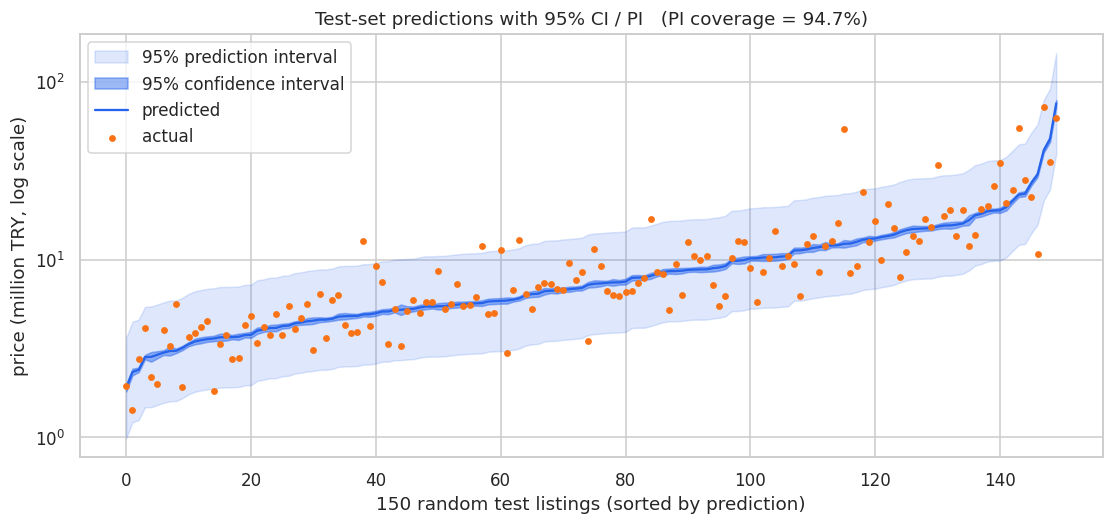

In [24]:
pred = final.get_prediction(X_te_c).summary_frame(alpha=0.05)
cover = np.mean((y_te >= pred.obs_ci_lower) & (y_te <= pred.obs_ci_upper))
print(f"95% PI empirical coverage on test set: {cover*100:.1f}%")

idx = np.random.default_rng(RNG).choice(len(y_te), 150, replace=False)
o = idx[np.argsort(pred["mean"].values[idx])]
x = np.arange(len(o))
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(x, np.exp(pred.obs_ci_lower.values[o])/1e6, np.exp(pred.obs_ci_upper.values[o])/1e6, color=ACC, alpha=.15, label="95% prediction interval")
ax.fill_between(x, np.exp(pred.mean_ci_lower.values[o])/1e6, np.exp(pred.mean_ci_upper.values[o])/1e6, color=ACC, alpha=.45, label="95% confidence interval")
ax.plot(x, np.exp(pred["mean"].values[o])/1e6, color=ACC, lw=1.5, label="predicted")
ax.scatter(x, np.exp(y_te[o])/1e6, s=12, color=ACC2, zorder=3, label="actual")
ax.set_yscale("log"); ax.set_xlabel("150 random test listings (sorted by prediction)"); ax.set_ylabel("price (million TRY, log scale)")
ax.set_title(f"Test-set predictions with 95% CI / PI   (PI coverage = {cover*100:.1f}%)"); ax.legend(loc="upper left")
save("09_pred_interval_test")

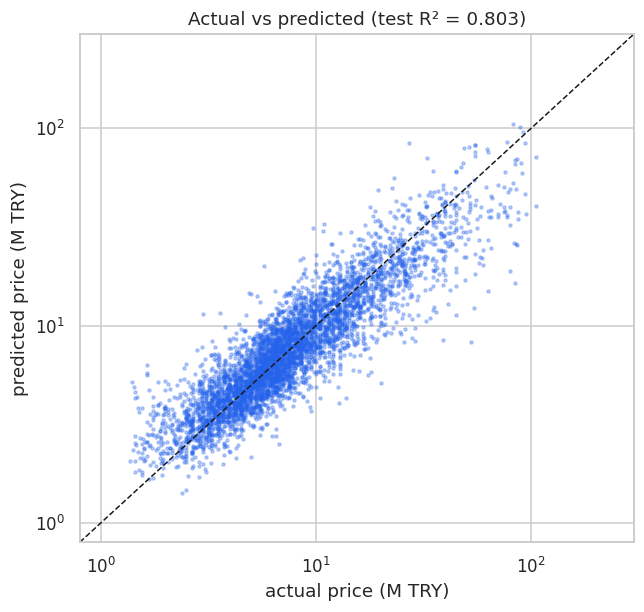

In [25]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(np.exp(y_te)/1e6, np.exp(yhat_te)/1e6, s=4, alpha=.3, color=ACC)
lim = [0.8, 300]; ax.plot(lim, lim, "k--", lw=1)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("actual price (M TRY)"); ax.set_ylabel("predicted price (M TRY)")
ax.set_title(f"Actual vs predicted (test R² = {r2_score(y_te, yhat_te):.3f})")
save("10_actual_vs_pred")

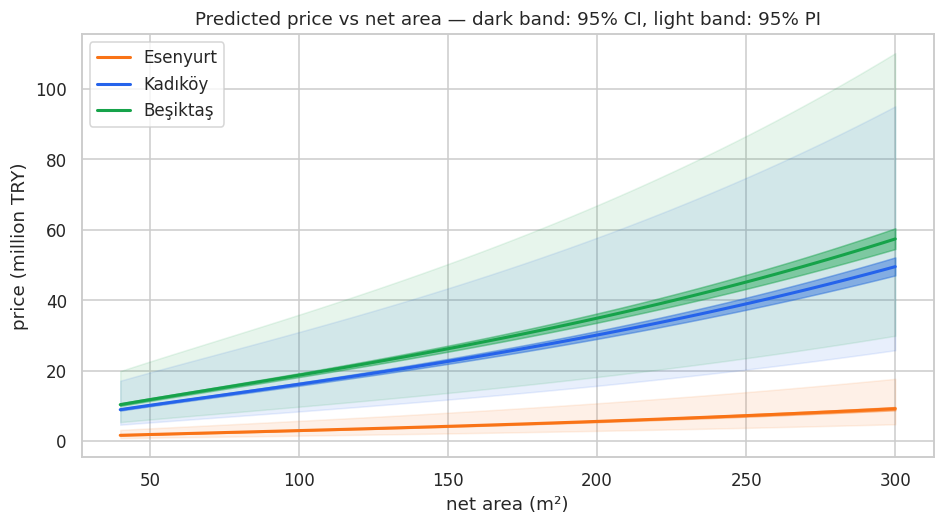

In [26]:
# Effect plot: price vs net area for a typical apartment in three districts, with CI & PI bands
base = X_tr[sel_cols].median().to_frame().T
for c in sel_cols:
    if c.startswith("district_"): base[c] = 0.0   # other categorical dummies keep their mode (median of 0/1)
grid = np.linspace(40, 300, 60)
fig, ax = plt.subplots(figsize=(10, 5))
for dist, col in [("Esenyurt", ACC2), ("Kadıköy", ACC), ("Beşiktaş", "#16a34a")]:
    G = pd.concat([base]*len(grid), ignore_index=True)
    G["log_net_sqm"] = np.log(grid)
    if "gross_sqm" in G: G["gross_sqm"] = grid * 1.18
    if f"district_{dist}" in G: G[f"district_{dist}"] = 1.0
    sf = final.get_prediction(sm.add_constant(G, has_constant="add")).summary_frame(alpha=.05)
    ax.fill_between(grid, np.exp(sf.obs_ci_lower)/1e6, np.exp(sf.obs_ci_upper)/1e6, color=col, alpha=.10)
    ax.fill_between(grid, np.exp(sf.mean_ci_lower)/1e6, np.exp(sf.mean_ci_upper)/1e6, color=col, alpha=.45)
    ax.plot(grid, np.exp(sf["mean"])/1e6, color=col, lw=2, label=dist)
ax.set_xlabel("net area (m²)"); ax.set_ylabel("price (million TRY)")
ax.set_title("Predicted price vs net area — dark band: 95% CI, light band: 95% PI"); ax.legend()
save("11_effect_area_district")

### 5.2 評估結論
- 多元線性回歸相較只用面積的簡單回歸，R² 大幅提升，主因是**行政區（地段）**提供了大量解釋力。
- Stepwise-AIC 刪除少數無貢獻的特徵群組後，測試表現與全模型相當但更精簡；RFE、Lasso 的結果與其高度一致，顯示選擇結果穩定。
- 殘差大致對稱，但尾部略厚（Q-Q 圖兩端偏離），代表仍有模型無法解釋的極端物件；log 轉換已明顯改善異質變異。
- 95% 預測區間的經驗覆蓋率接近 95%，區間可用於實務估價的「合理價格範圍」。
- **限制**：未使用 neighborhood（街區）等更細的地段資訊；房價可能存在非線性交互作用（例如面積 × 行政區），線性模型無法完全捕捉。

## 6. Deployment（部署）

In [27]:
# Export the final model for the GitHub Pages predictor (pure JS, no server)
cols = ["const"] + sel_cols
export = {
    "columns": cols,
    "coef": final.params[cols].tolist(),
    "cov": final.cov_params().loc[cols, cols].values.tolist(),
    "sigma2": float(final.scale),
    "df_resid": float(final.df_resid),
    "t975": float(__import__("scipy").stats.t.ppf(0.975, final.df_resid)),
    "num_defaults": {c: float(X_tr[c].median()) for c in sel_cols if c in NUM},
    "categories": {g: sorted(df[g].unique().tolist()) for g in CAT if g in selected},
    "base_levels": {g: sorted(df[g].unique().tolist())[0] for g in CAT if g in selected},
    "metrics": {k: {m: round(float(v), 4) for m, v in d.items()} for k, d in res.T.to_dict().items()},
    "pi_coverage": float(cover), "n_train": int(len(y_tr)), "n_test": int(len(y_te)),
    "selected_groups": selected, "dropped_groups": remaining,
}
with open("docs/model.json", "w", encoding="utf-8") as f: json.dump(export, f, ensure_ascii=False)
with open("docs/model.js", "w", encoding="utf-8") as f:   # same data as a script, so the page also works when opened locally
    f.write("window.MODEL = " + json.dumps(export, ensure_ascii=False) + ";")
res.round(4).to_csv("docs/assets/model_comparison.csv")
hist.round(4).to_csv("docs/assets/stepwise_history.csv", index=False)
coef.round(5).to_csv("docs/assets/final_coefficients.csv")
print("exported", len(cols), "coefficients")

exported 67 coefficients


- 最終模型的係數、共變異數矩陣與殘差變異數已匯出成 `docs/model.json`。
- 網頁 `docs/index.html` 部署在 **GitHub Pages**，使用者輸入房屋條件後，瀏覽器端以 JavaScript 計算：
  - 點預測 ŷ = xᵀβ
  - 95% 預測區間 ŷ ± t₀.₉₇₅ · √(σ² + xᵀ Cov(β) x)，再以 e^(·) 轉回里拉
- 不需後端伺服器，可隨資料更新重新執行 notebook 後覆蓋 `model.json`。